 # bank_customer_response_prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

In [2]:
loan_data = pd.read_csv("loan_detection.csv")

In [3]:
# Basic info about the dataset
print(loan_data.info())  # Check data types and missing values
print(loan_data.describe())  # Summary statistics
print(loan_data.head())  # Display the first few rows of data


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 60 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   age                            41188 non-null  int64
 1   campaign                       41188 non-null  int64
 2   pdays                          41188 non-null  int64
 3   previous                       41188 non-null  int64
 4   no_previous_contact            41188 non-null  int64
 5   not_working                    41188 non-null  int64
 6   job_admin.                     41188 non-null  int64
 7   job_blue-collar                41188 non-null  int64
 8   job_entrepreneur               41188 non-null  int64
 9   job_housemaid                  41188 non-null  int64
 10  job_management                 41188 non-null  int64
 11  job_retired                    41188 non-null  int64
 12  job_self-employed              41188 non-null  int64
 13  job_services    

In [4]:
# Check for missing values
missing_values = loan_data.isnull().sum()
print("Missing values per column:\n", missing_values[missing_values > 0])

Missing values per column:
 Series([], dtype: int64)


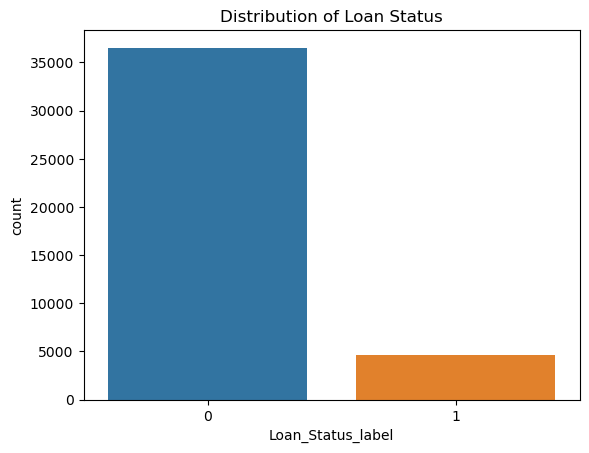

In [5]:
# Visualize the distribution of the target variable
sns.countplot(x='Loan_Status_label', data=loan_data)
plt.title('Distribution of Loan Status')
plt.show()


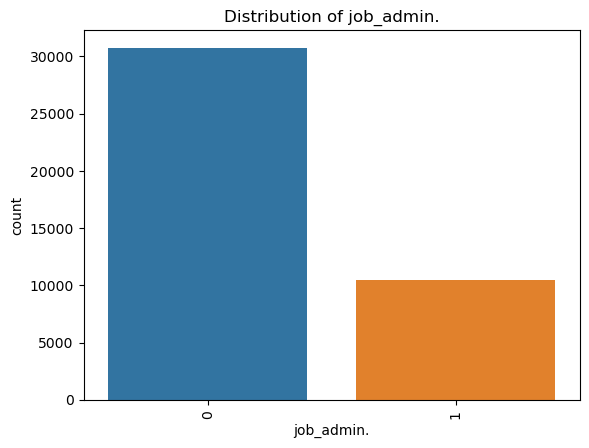

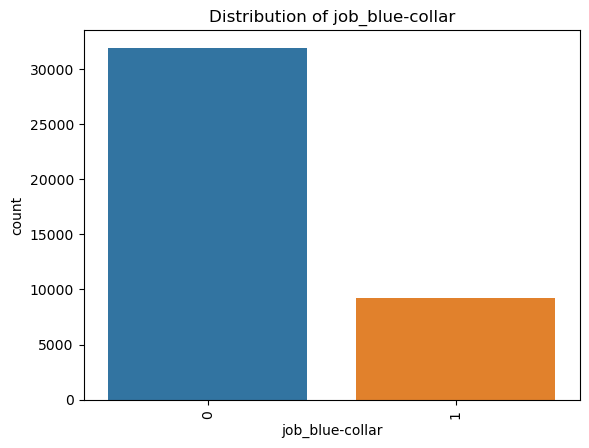

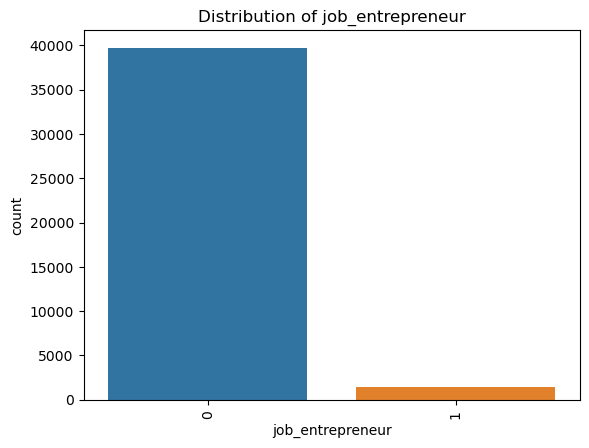

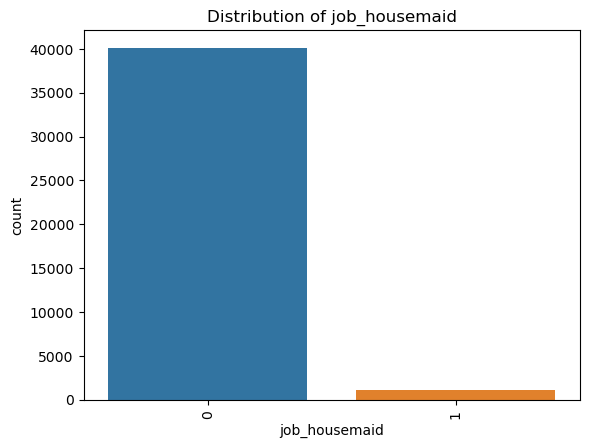

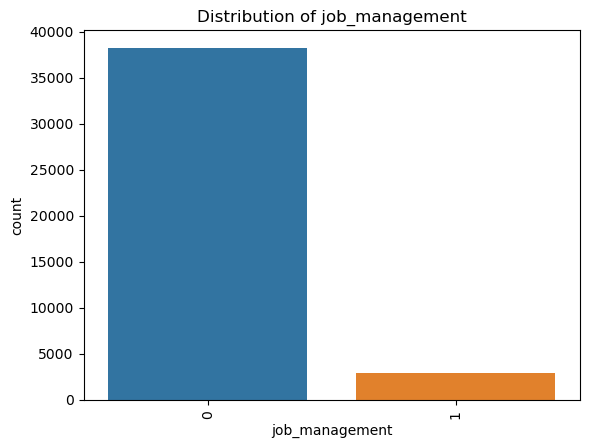

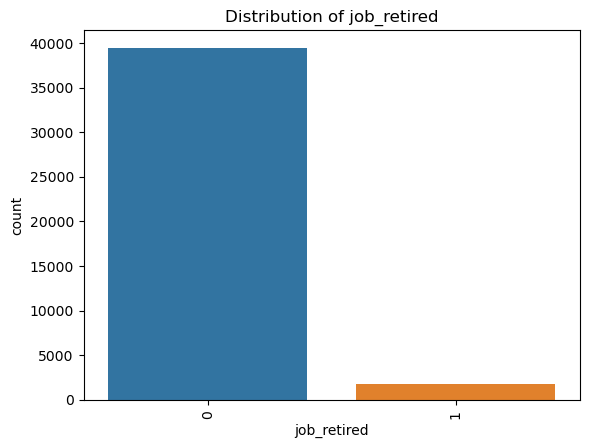

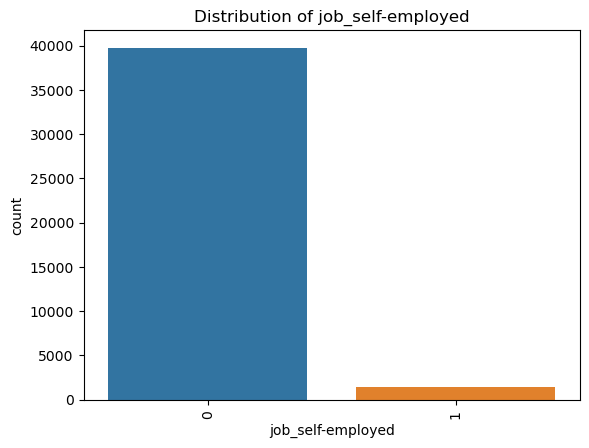

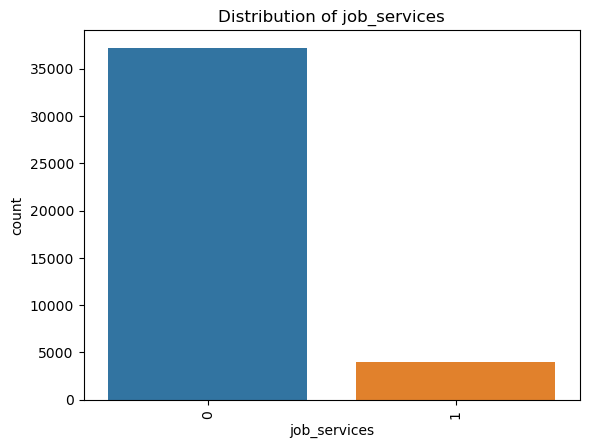

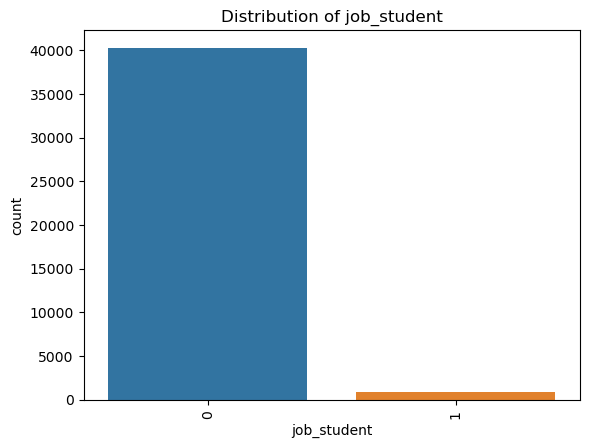

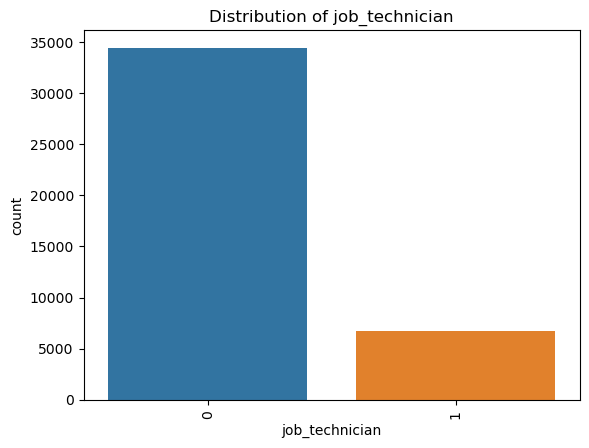

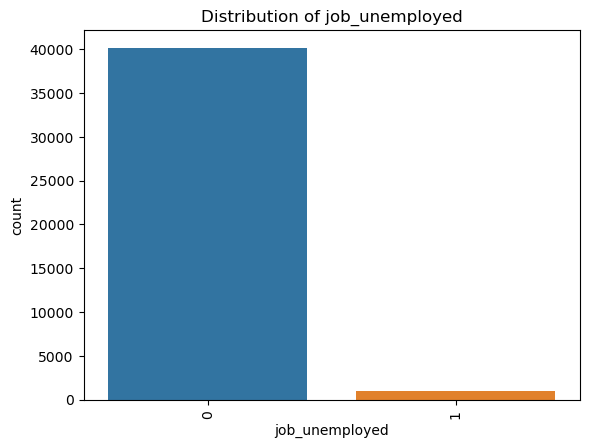

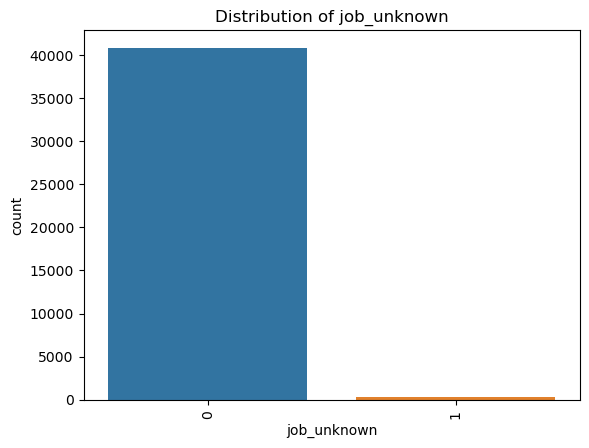

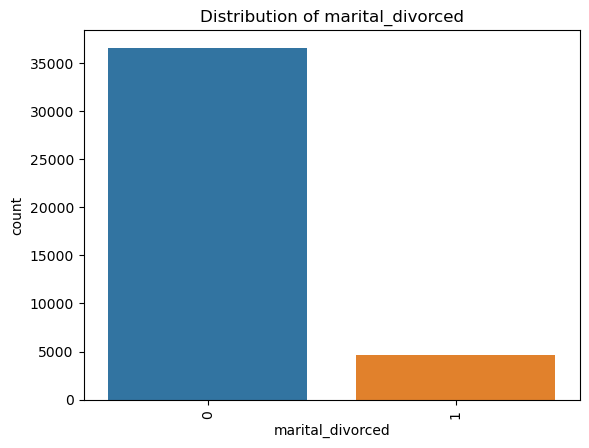

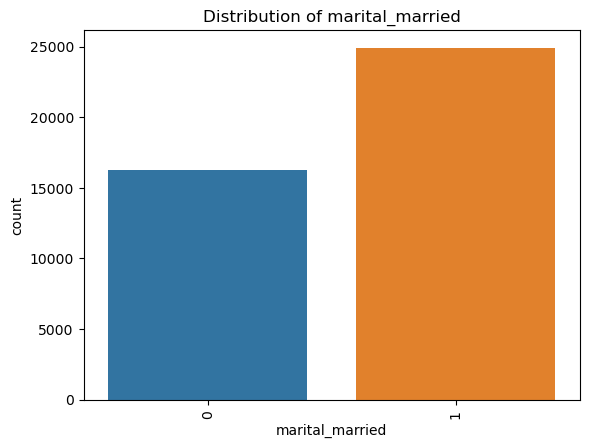

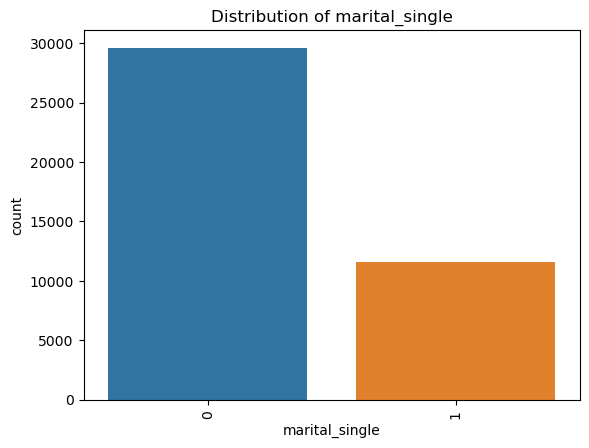

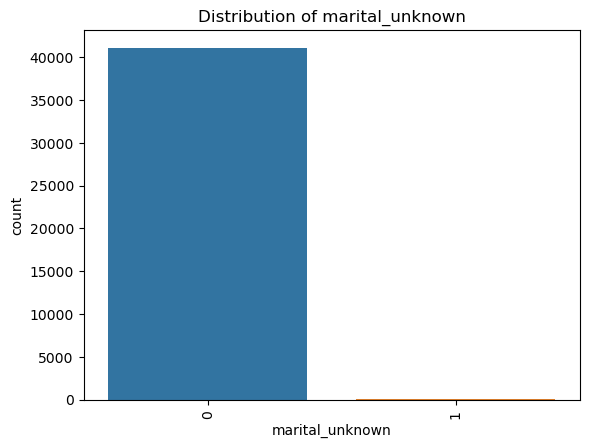

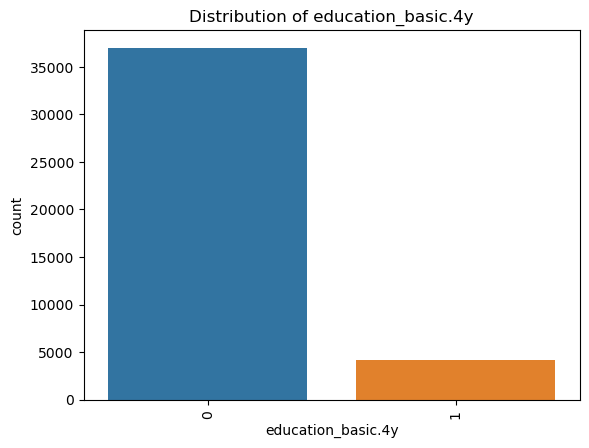

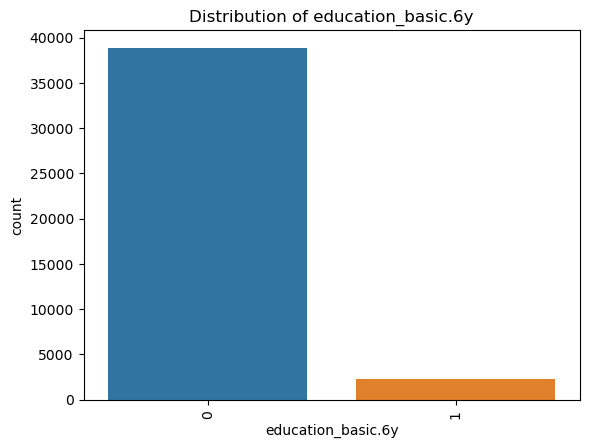

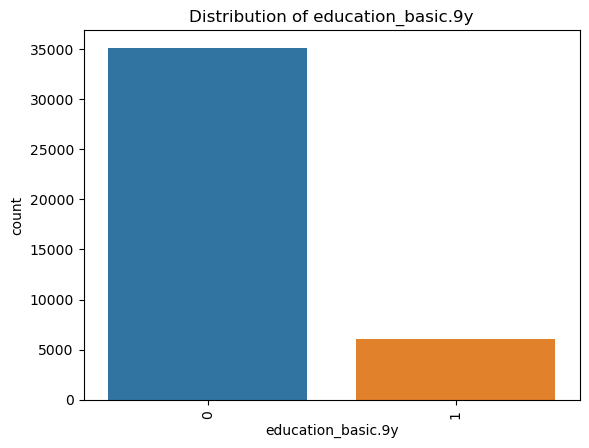

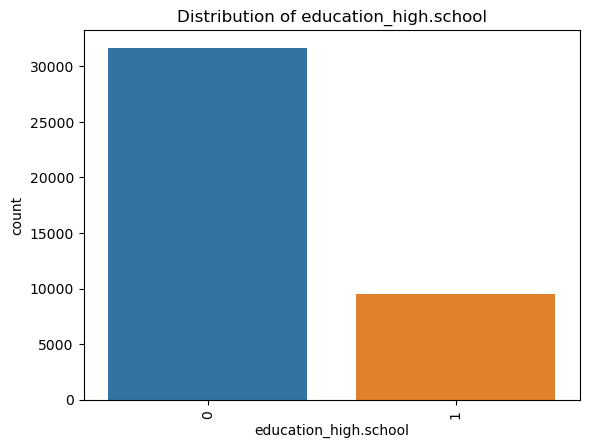

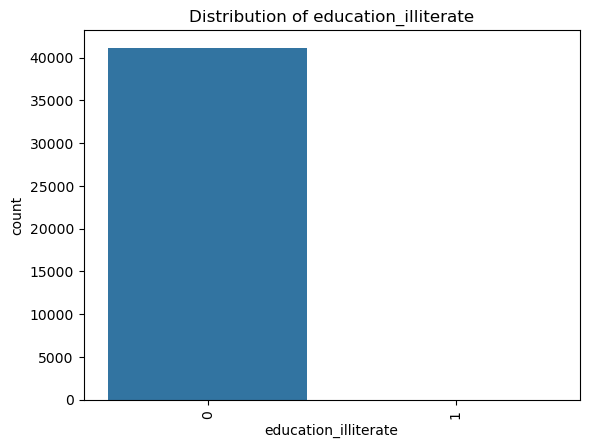

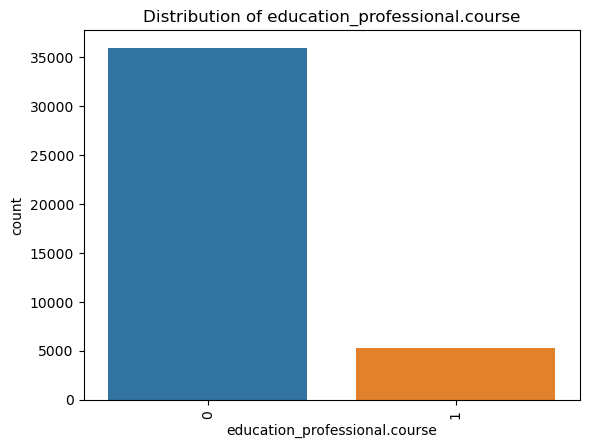

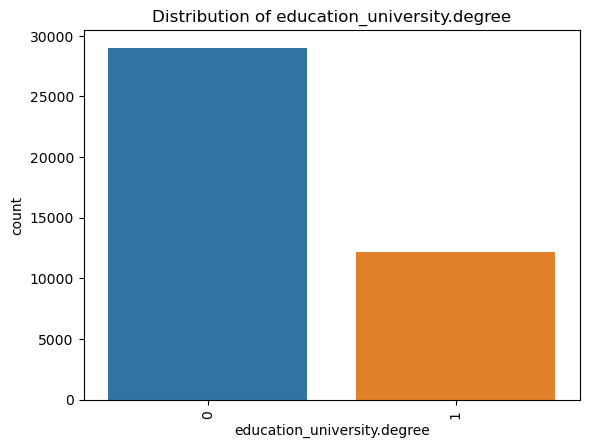

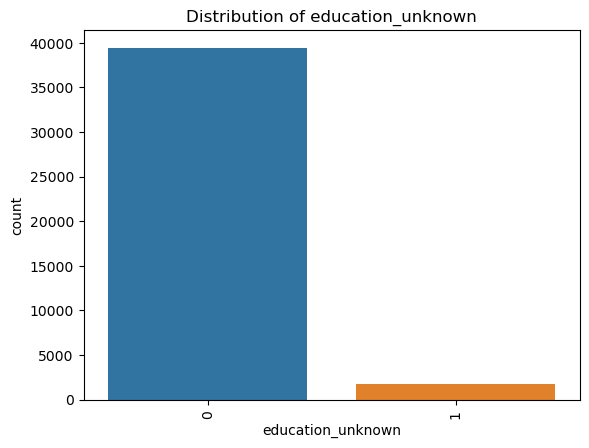

In [6]:
# Analyze categorical variables
categorical_columns = [col for col in loan_data.columns if 'job_' in col or 'education_' in col or 'marital_' in col]
for col in categorical_columns:
    sns.countplot(x=col, data=loan_data)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=90)
    plt.show()

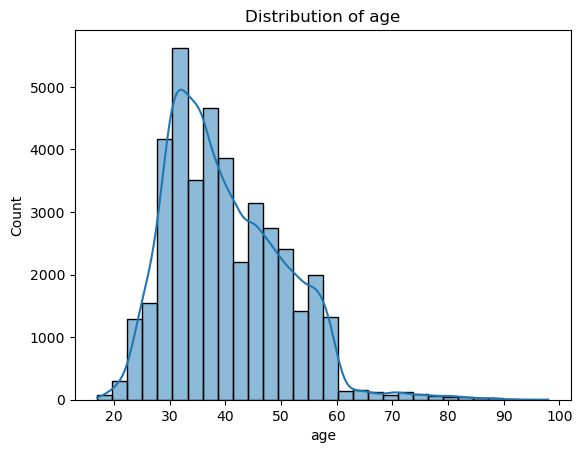

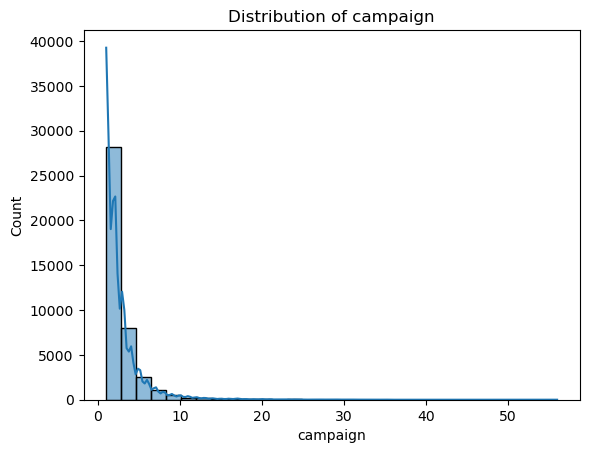

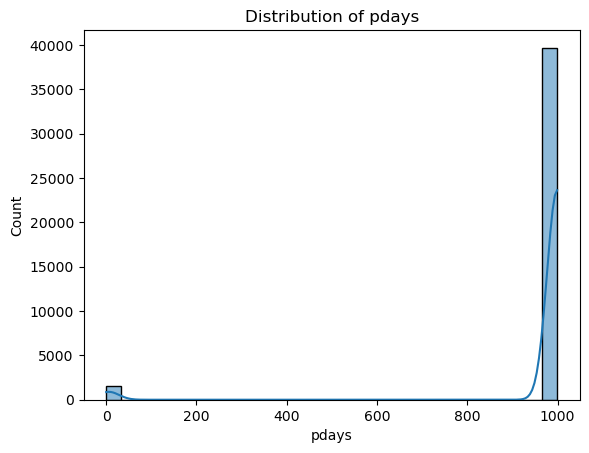

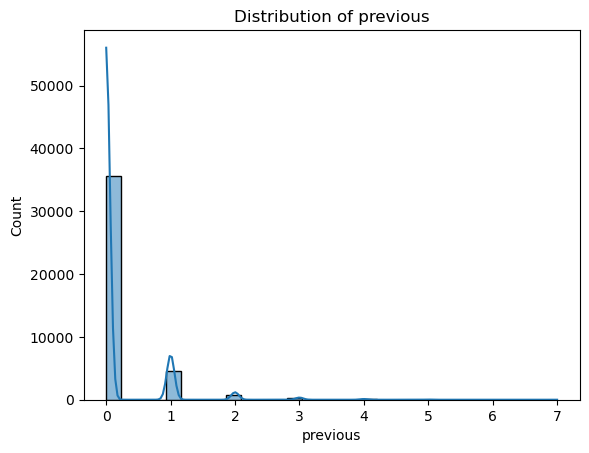

In [7]:
# Visualizing distribution of age and other numeric columns
numeric_columns = ['age', 'campaign', 'pdays', 'previous']
for col in numeric_columns:
    sns.histplot(loan_data[col], bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()


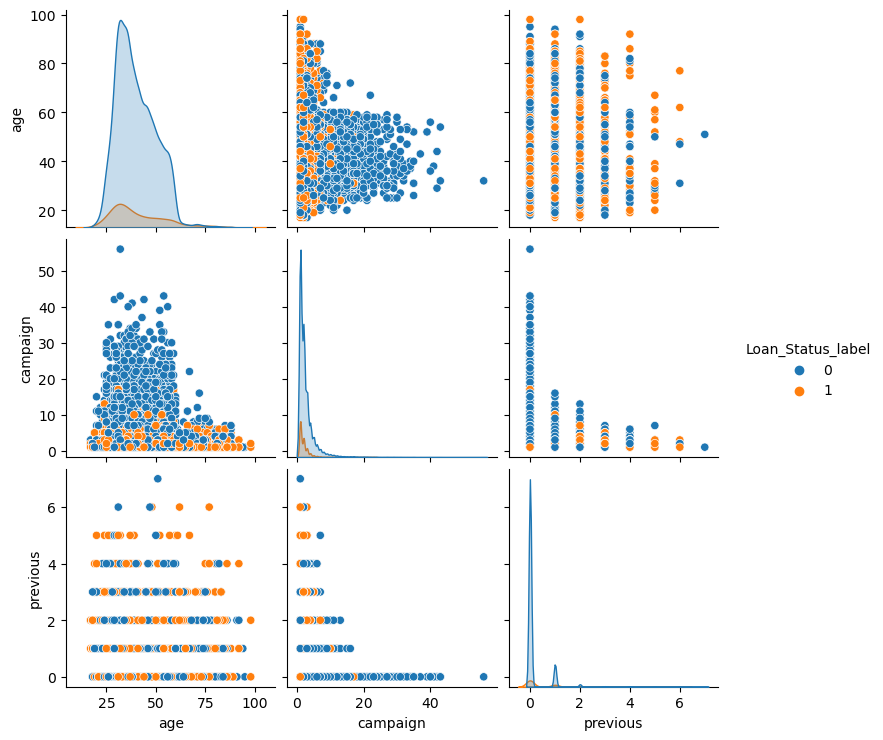

In [8]:
# Pairplot to analyze relationships
sns.pairplot(loan_data[['age', 'campaign', 'previous', 'Loan_Status_label']], hue='Loan_Status_label')
plt.show()

In [9]:
# Split the data into features and target variable
X = loan_data.drop(columns=['Loan_Status_label'])
y = loan_data['Loan_Status_label']

In [10]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
X_train

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
12556,40,2,999,0,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
35451,31,4,999,0,1,0,1,0,0,0,...,0,0,0,1,0,0,0,0,1,0
30592,59,6,999,1,1,1,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
17914,43,5,999,0,1,0,0,0,0,1,...,0,0,0,0,0,1,0,0,1,0
3315,39,2,999,0,1,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,58,2,999,0,1,1,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
11284,37,1,999,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
38158,35,1,4,1,0,0,1,0,0,0,...,1,0,0,0,1,0,0,0,0,1
860,40,2,999,0,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0


In [12]:
X_test

,age,campaign,pdays,previous,no_previous_contact,not_working,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
32884,57,1,999,1,1,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
3169,55,2,999,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
32206,33,1,999,1,1,0,0,1,0,0,...,0,0,1,0,0,0,0,1,0,0
9403,36,4,999,0,1,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
14020,27,2,999,0,1,0,0,0,0,1,...,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12322,27,1,999,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
23440,41,7,999,0,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
29431,46,12,999,1,1,0,0,0,1,0,...,0,0,0,1,0,0,0,1,0,0
16627,31,2,999,0,1,0,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0


In [13]:
# Standardize the features (optional but beneficial for some models like Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled
X_test_scaled

array([[ 1.62735672, -0.56620036,  0.19466067, ...,  2.93701532,
        -2.51020518, -0.18496534],
       [ 1.4357066 , -0.20624161,  0.19466067, ..., -0.34048171,
         0.39837381, -0.18496534],
       [-0.67244473, -0.56620036,  0.19466067, ...,  2.93701532,
        -2.51020518, -0.18496534],
       ...,
       [ 0.57328106,  3.39334585,  0.19466067, ...,  2.93701532,
        -2.51020518, -0.18496534],
       [-0.86409485, -0.20624161,  0.19466067, ..., -0.34048171,
         0.39837381, -0.18496534],
       [ 1.81900684, -0.20624161,  0.19466067, ..., -0.34048171,
         0.39837381, -0.18496534]])

In [14]:
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
random_forest = RandomForestClassifier(class_weight='balanced', random_state=42)
decision_tree = DecisionTreeClassifier(class_weight='balanced', random_state=42)
random_forest 

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [15]:
decision_tree

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are 

In [16]:

# Train and evaluate Logistic Regression
log_reg.fit(X_train_scaled, y_train)
y_pred_log_reg = log_reg.predict(X_test_scaled)
log_reg_accuracy = accuracy_score(y_test, y_pred_log_reg)
y_pred_log_reg


array([0, 0, 0, ..., 0, 1, 0], dtype=int64)

In [17]:
log_reg_accuracy

0.798980335032775

In [18]:
# Train and evaluate Random Forest
random_forest.fit(X_train, y_train)  # No scaling needed for Random Forest
y_pred_rf = random_forest.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

In [19]:
y_pred_rf 

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [20]:
rf_accuracy

0.8606457878125758

In [21]:
# Train and evaluate Decision Tree
decision_tree.fit(X_train, y_train)  # No scaling needed for Decision Tree
y_pred_dt = decision_tree.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

In [22]:
y_pred_dt

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [23]:
dt_accuracy

0.829691672736101

In [24]:
# Compare the accuracies
print(f"Logistic Regression Accuracy: {log_reg_accuracy:.2f}")
print(f"Random Forest Accuracy: {rf_accuracy:.2f}")
print(f"Decision Tree Accuracy: {dt_accuracy:.2f}")

Logistic Regression Accuracy: 0.80
Random Forest Accuracy: 0.86
Decision Tree Accuracy: 0.83


In [25]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_log_reg)
print("\nConfusion Matrix:")
print(conf_matrix)


Confusion Matrix:
[[6073 1230]
 [ 426  509]]


In [26]:
from sklearn.metrics import f1_score, recall_score, precision_score
print("Recall:", recall_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))

Recall: 0.38181818181818183
Precision: 0.3851132686084142
F1: 0.38345864661654133


In [27]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_log_reg))


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      7303
           1       0.29      0.54      0.38       935

    accuracy                           0.80      8238
   macro avg       0.61      0.69      0.63      8238
weighted avg       0.86      0.80      0.82      8238



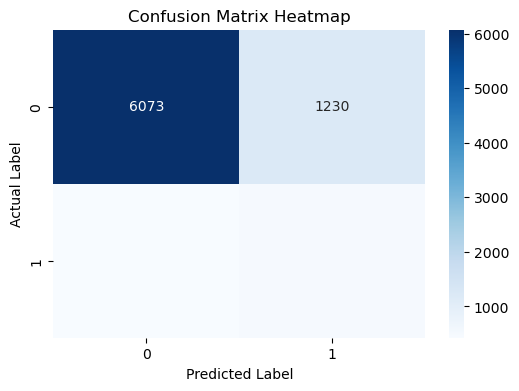

In [28]:
# Plot the heatmap of the confusion matrix
plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap='Blues')
plt.title('Confusion Matrix Heatmap')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [29]:
# Compare the accuracies
model_accuracies = {
    'Logistic Regression': log_reg_accuracy,
    'Random Forest': rf_accuracy,
    'Decision Tree': dt_accuracy
}

In [30]:
model_accuracies

{'Logistic Regression': 0.798980335032775,
 'Random Forest': 0.8606457878125758,
 'Decision Tree': 0.829691672736101}

In [31]:
# Balance the classes (about 8 "no" customers for every 1 "yes")
scale = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(scale_pos_weight=scale, random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
print("XGBoost Accuracy:", xgb_accuracy)
print("Recall:", recall_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))

XGBoost Accuracy: 0.8177955814518086
Recall: 0.5219251336898396
Precision: 0.3164721141374838
F1: 0.3940250302785628


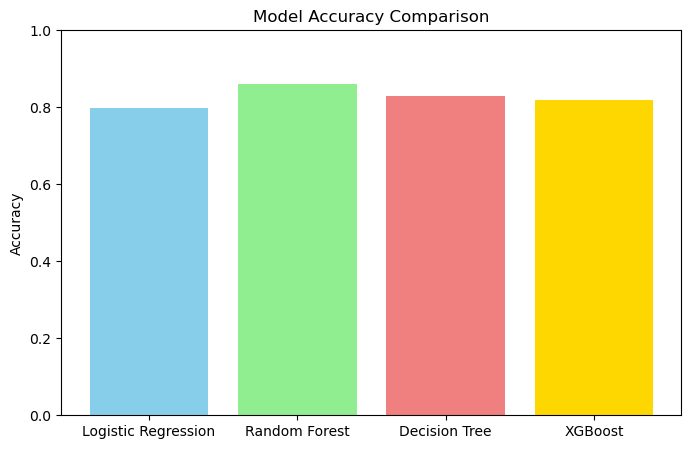

In [32]:
# Plot the accuracy graph

model_accuracies['XGBoost'] = xgb_accuracy

plt.figure(figsize=(8, 5))
plt.bar(model_accuracies.keys(), model_accuracies.values(),
        color=['skyblue', 'lightgreen', 'lightcoral', 'gold'])
plt.ylim(0, 1)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()

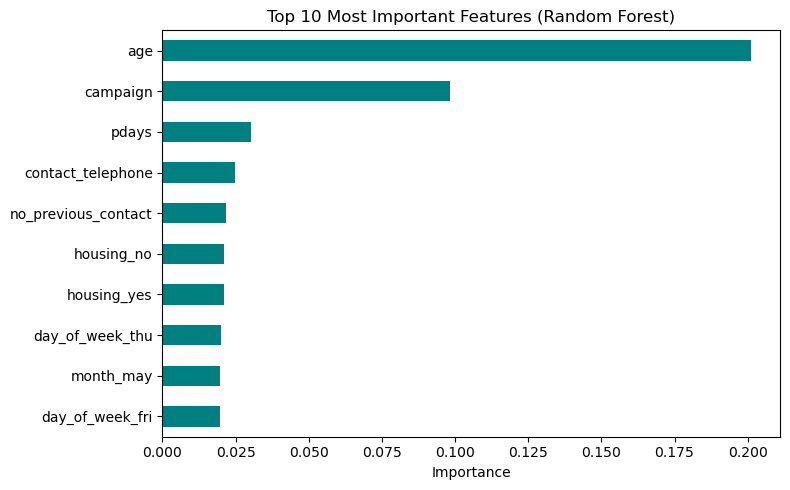

age                    0.200999
campaign               0.098348
pdays                  0.030395
contact_telephone      0.024944
no_previous_contact    0.021861
housing_no             0.021189
housing_yes            0.021031
day_of_week_thu        0.019927
month_may              0.019707
day_of_week_fri        0.019677
dtype: float64


In [33]:
importances = pd.Series(random_forest.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind='barh', color='teal')
plt.title('Top 10 Most Important Features (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')  # this will crete a file feature_importance in the same folder as the notebook 
plt.show()

print(top10)